# Engineered Learning Problems on Noisy Quantum Processors
[arXiv:2610.41848](https://arxiv.org/abs/2610.41848). Expects the Zenodo data in `data/`.

In [1]:
import csv
import hashlib

import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import t as student_t
from joblib import Parallel, delayed
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.metrics.pairwise import cosine_similarity, laplacian_kernel, rbf_kernel
from sklearn.model_selection import GridSearchCV, cross_val_score
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

DATA = "data"
# Download check: every file must match its SHA-256 in MANIFEST.csv
bad = [r["path"] for r in csv.DictReader(open(f"{DATA}/MANIFEST.csv"))
       if hashlib.sha256(open(f"{DATA}/{r['path']}", "rb").read()).hexdigest() != r["sha256"]]
assert not bad, f"corrupt or changed files: {bad}"

gap = np.load(f"{DATA}/accuracies/gap_test.npz")
FAMILIES = sorted({k.split("/")[0] for k in gap.files})
CLASSICAL = ["rbf (ref)", "rbf (grid)", "linear", "poly d=2", "poly d=3", "sigmoid", "laplacian", "cosine",
             "hist gbm", "random forest", "mlp"]
T_OF = {"15q": 3, "15q_4trot": 4, "15q_5trot": 5, "15q_6trot": 6, "15q_10trot": 10}  # label key "15q" is T=3


def acc(fam, model, tuning="cv"):
    return gap[f"{fam}/{tuning}/{model}"]


def best_classical(fam, tuning="cv"):
    return max(CLASSICAL, key=lambda m: acc(fam, m, tuning).mean())



## Models (Appendix A)
Each model picks its hyperparameters by 5-fold CV on the training set, or by test accuracy when test-tuned.

In [2]:
MULT = [0.25, 0.5, 1, 2, 3, 4, 5, 20]  # gamma = mult / (d * var), on the training features
C_GRID = [0.006, 0.015, 0.03, *2.0 ** np.arange(-4, 11)]


def gamma_grid(x, mult=MULT):
    return np.array(mult) / (x.shape[1] * (np.var(x) + 1e-8))


def challenger_accuracy(f_tr, f_te, y_tr, y_te):
    """PQK: RBF on the projected features, best gamma by 5-fold CV."""
    gammas = gamma_grid(f_tr)
    fits = [GridSearchCV(SVC(kernel="precomputed"), {"C": C_GRID}, cv=5).fit(rbf_kernel(f_tr, gamma=g), y_tr)
            for g in gammas]
    i = int(np.argmax([s.best_score_ for s in fits]))
    return fits[i].score(rbf_kernel(f_te, f_tr, gamma=gammas[i]), y_te)


def candidates(model, x_tr, x_te, gammas, gstar=None):
    svc = lambda **kw: [(SVC(C=c, **kw), x_tr, x_te) for c in C_GRID]
    pre = lambda a, b: [(SVC(kernel="precomputed", C=c), a, b) for c in C_GRID]
    est = lambda make, grid: [(make(*p), x_tr, x_te) for p in grid]
    return {
        "rbf (ref)": lambda: svc(kernel="rbf", gamma=gstar),
        "rbf (grid)": lambda: [c for g in gammas for c in svc(kernel="rbf", gamma=g)],
        "linear": lambda: svc(kernel="linear"),
        "poly d=2": lambda: svc(kernel="poly", degree=2),
        "poly d=3": lambda: svc(kernel="poly", degree=3),
        "sigmoid": lambda: svc(kernel="sigmoid"),
        "laplacian": lambda: [c for g in gammas
                              for c in pre(laplacian_kernel(x_tr, x_tr, gamma=g), laplacian_kernel(x_te, x_tr, gamma=g))],
        "cosine": lambda: pre(cosine_similarity(x_tr, x_tr), cosine_similarity(x_te, x_tr)),
        "hist gbm": lambda: est(lambda m, lr: HistGradientBoostingClassifier(max_iter=m, learning_rate=lr, random_state=0),
                                [(m, lr) for m in (100, 300) for lr in (0.05, 0.1)]),
        "random forest": lambda: est(lambda n, d: RandomForestClassifier(n_estimators=n, max_depth=d, random_state=0),
                                     [(n, d) for n in (200, 500) for d in (None, 5)]),
        "mlp": lambda: est(lambda h, a: make_pipeline(StandardScaler(), MLPClassifier(hidden_layer_sizes=h, alpha=a,
                                                                                      max_iter=2000, random_state=0)),
                           [(h, a) for h in ((64,), (128, 64)) for a in (1e-3, 1e-1)]),
    }[model]()


def classical_accuracy(model, x_tr, x_te, y_tr, y_te, gammas, gstar=None, test_tuned=False):
    cands = candidates(model, x_tr, x_te, gammas, gstar)
    if test_tuned:
        return max(m.fit(a, y_tr).score(b, y_te) for m, a, b in cands)
    m, a, b = max(cands, key=lambda c: cross_val_score(c[0], c[1], y_tr, cv=5).mean())
    return m.fit(a, y_tr).score(b, y_te)

## Table II, Figs. 3, 7, 11

In [3]:
def corrected_ttest(diff, n_train=100, n_test=50, alpha=0.05):
    d = diff.reshape(10, 10).mean(1)
    J = len(d)
    se = np.sqrt(1 / J + n_test / n_train) * d.std(ddof=1)
    crit = student_t.ppf(1 - alpha, J - 1)
    return d.mean(), d.mean() - crit * se, d.mean() / se > crit  # gap, 95% lower bound, gap found


ORDER = ["15q", "15q_4trot", "15q_5trot", "15q_6trot", "15q_10trot",
         *[f"{n}q_{t}trot" for n in (30, 45) for t in (3, 4, 5, 6, 10)],
         "15q_10trot_orig", "15q_10trot_zne", "15q_10trot", "15q_10trot_rem", "15q_10trot_apt"]
print(f"{'family':<17}{'gap (CV)':>9}{'lower bd':>10}{'test-tuned':>12}  t-test")
for fam in ORDER:
    if fam not in FAMILIES:
        print(f"{fam:<17} not released")
        continue
    q = acc(fam, "pqk (_2)")
    g, lb, found = corrected_ttest(q - acc(fam, best_classical(fam)))
    tt = q.mean() - acc(fam, best_classical(fam, "test_tuned"), "test_tuned").mean()
    print(f"{fam:<17}{g:+9.3f}{lb:+10.3f}{tt:+12.3f}  {'gap' if found else 'no gap'}")

family            gap (CV)  lower bd  test-tuned  t-test
15q                 +0.300    +0.238      +0.250  gap
15q_4trot           +0.287    +0.247      +0.237  gap
15q_5trot           +0.248    +0.190      +0.205  gap
15q_6trot           +0.184    +0.101      +0.159  gap
15q_10trot          +0.040    -0.070      +0.017  no gap
30q_3trot           +0.281    +0.239      +0.200  gap
30q_4trot           +0.246    +0.188      +0.209  gap
30q_5trot           +0.224    +0.164      +0.162  gap
30q_6trot           +0.228    +0.162      +0.168  gap
30q_10trot          +0.181    +0.115      +0.124  gap
45q_3trot           +0.245    +0.139      +0.175  gap
45q_4trot           +0.242    +0.163      +0.183  gap
45q_5trot           +0.256    +0.193      +0.201  gap
45q_6trot           +0.242    +0.188      +0.198  gap
45q_10trot          +0.170    +0.065      +0.139  gap
15q_10trot_orig     +0.059    -0.101      +0.035  no gap
15q_10trot_zne      +0.139    +0.078      +0.106  gap
15q_10trot         

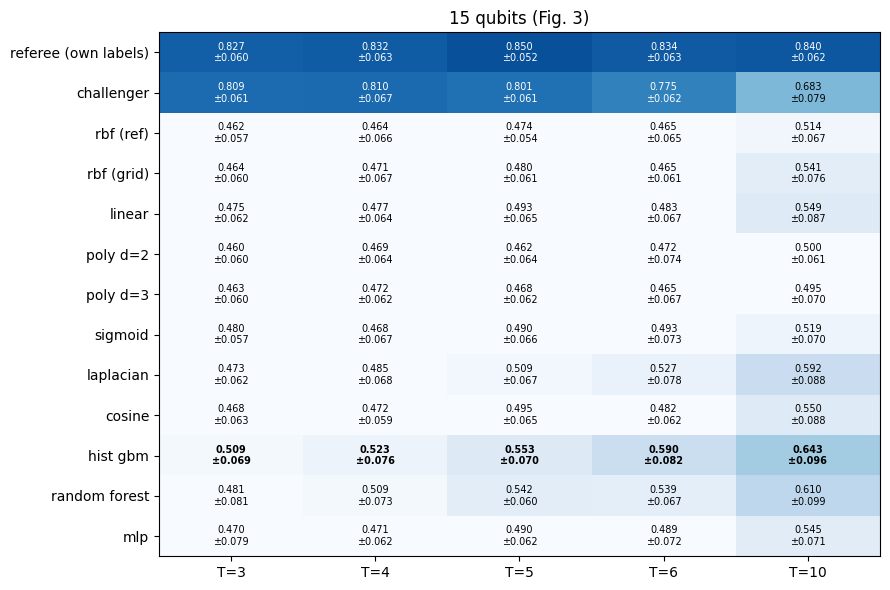

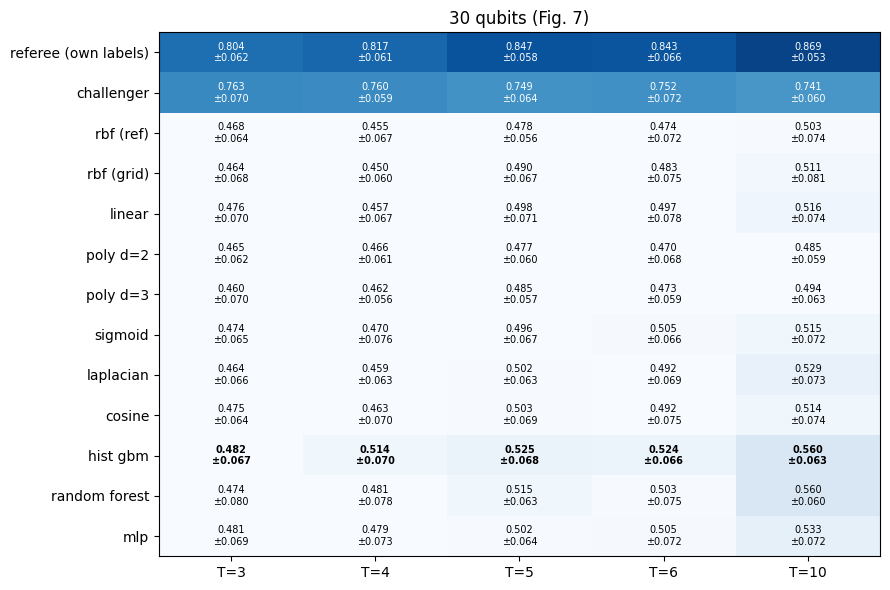

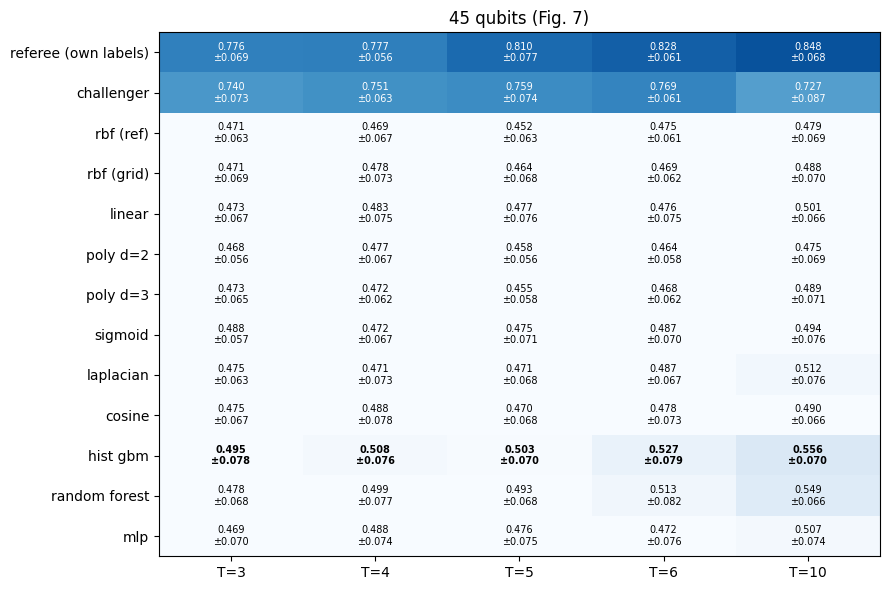

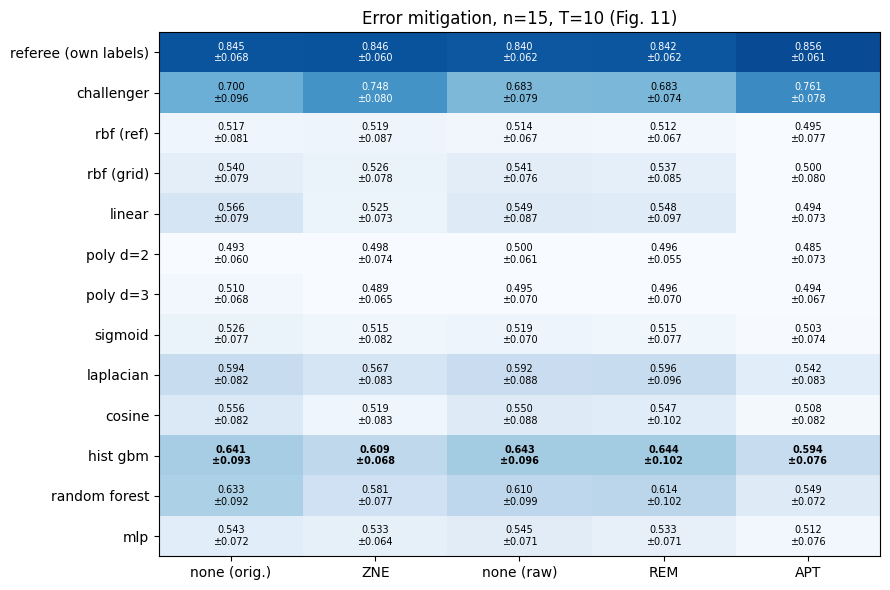

In [4]:
def heatmap(fams, cols, title):
    rows = ["pqk (base, self)", "pqk (_2)", *CLASSICAL]
    names = ["referee (own labels)", "challenger", *CLASSICAL]
    mean = np.array([[acc(f, m).mean() for f in fams] for m in rows])
    sd = np.array([[acc(f, m).std() for f in fams] for m in rows])
    fig, ax = plt.subplots(figsize=(1.3 * len(fams) + 2.5, 6))
    ax.imshow(mean, cmap="Blues", vmin=0.5, vmax=0.9, aspect="auto")
    for i in range(len(rows)):
        for j, f in enumerate(fams):
            bold = rows[i] == best_classical(f)
            ax.text(j, i, f"{mean[i, j]:.3f}\n±{sd[i, j]:.3f}", ha="center", va="center", fontsize=7,
                    color="w" if mean[i, j] > 0.7 else "k", fontweight="bold" if bold else "normal")
    ax.set(xticks=range(len(fams)), xticklabels=cols, yticks=range(len(rows)), yticklabels=names, title=title)
    plt.tight_layout()
    plt.show()


heatmap(["15q", "15q_4trot", "15q_5trot", "15q_6trot", "15q_10trot"], [f"T={t}" for t in (3, 4, 5, 6, 10)],
        "15 qubits (Fig. 3)")
for n in (30, 45):
    heatmap([f"{n}q_{t}trot" for t in (3, 4, 5, 6, 10)], [f"T={t}" for t in (3, 4, 5, 6, 10)],
            f"{n} qubits (Fig. 7)")
em = [f for f in ["15q_10trot_orig", "15q_10trot_zne", "15q_10trot", "15q_10trot_rem", "15q_10trot_apt"] if f in FAMILIES]
heatmap(em, [{"15q_10trot_orig": "none (orig.)", "15q_10trot_zne": "ZNE", "15q_10trot": "none (raw)",
              "15q_10trot_rem": "REM", "15q_10trot_apt": "APT"}[f] for f in em], "Error mitigation, n=15, T=10 (Fig. 11)")

## Tables III and IV, Fig. 4

In [5]:
def feats(n, t, suf):
    return np.load(f"{DATA}/features/fashion_mnist_pqk_features_{n}q_{t}trotter_{suf}.npy")


def K(f):
    return rbf_kernel(f, gamma=1 / (f.shape[1] * (np.var(f) + 1e-8)))


def cka(A, B):
    H = np.eye(len(A)) - 1 / len(A)
    a, b = H @ A @ H, H @ B @ H
    return (a * b).sum() / np.sqrt((a * a).sum() * (b * b).sum())


I = feats(15, 10, "IDEALSIM600")
KI = K(I)
ideal = np.load(f"{DATA}/accuracies/em_ideal.npz")
ROWS = [("original run", "none", "e_orig", "g_orig"), ("original run", "ZNE", "zne_e", "zne_g"),
        ("raw counts", "none", "e", "g"), ("raw counts", "REM", "rem_e", "rem_g"),
        ("raw counts", "APT", "apt_e", "apt_g")]
CR = {}  # (baseline, mitigation, device) -> (c, |r|), for Fig. 4
print(f"{'baseline':<13}{'mitig.':<7}{'c':>15}{'|r|':>15}{'eps':>15}{'d_F':>15}{'CKA':>15}{'acc (ideal)':>15}")
for base, mit, e, g in ROWS:
    if e not in ideal.files:
        print(f"{base:<13}{mit:<7} not released")
        continue
    cols = []
    for suf, dev in ((e, "Emerald"), (g, "Garnet")):
        F = feats(15, 10, suf)
        c = (F * I).sum() / (I * I).sum()
        r = np.linalg.norm(F - c * I) / np.linalg.norm(I)
        CR[base, mit, dev] = c, r
        KF = K(F)
        cols.append((c, r, r / c, np.linalg.norm(KF - KI) / np.linalg.norm(KI), cka(KF, KI), ideal[suf].mean()))
    print(f"{base:<13}{mit:<7}" + "".join(f"{a:>8.3f}/{b:.3f}" for a, b in zip(*cols)))
print(f"ideal kernel {ideal['ideal'].mean():.3f}, best classical (hist gbm) {ideal['hist gbm'].mean():.3f}")

baseline     mitig.               c            |r|            eps            d_F            CKA    acc (ideal)
original run none      0.552/0.392   0.342/0.298   0.619/0.760   0.233/0.262   0.563/0.488   0.773/0.745
original run ZNE       0.825/0.564   0.478/0.430   0.580/0.762   0.199/0.284   0.633/0.503   0.754/0.737
raw counts   none      0.560/0.283   0.326/0.314   0.582/1.108   0.194/0.360   0.572/0.355   0.768/0.701


raw counts   REM       0.569/0.282   0.331/0.338   0.582/1.199   0.196/0.334   0.569/0.354   0.770/0.703
raw counts   APT       0.684/0.400   0.189/0.193   0.276/0.483   0.139/0.191   0.903/0.700   0.838/0.763
ideal kernel 0.863, best classical (hist gbm) 0.588


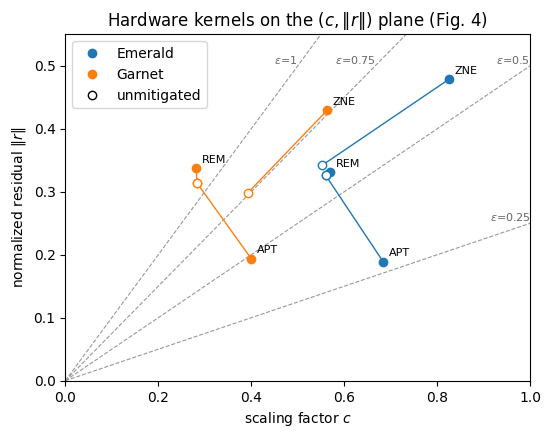

In [6]:
fig, ax = plt.subplots(figsize=(6, 4.5))
c = np.linspace(0, 1, 2)
for eps in (1, 0.75, 0.5, 0.25):
    ax.plot(c, eps * c, "--", color="0.6", lw=0.8)
    ax.text(0.5 / eps if eps > 0.5 else 1, 0.5 if eps > 0.5 else eps, f"$\\varepsilon$={eps}", color="0.4", fontsize=8,
            ha="right", va="bottom")
for dev, col in (("Emerald", "C0"), ("Garnet", "C1")):
    for base, mit in (("original run", "ZNE"), ("raw counts", "REM"), ("raw counts", "APT")):
        if (base, mit, dev) not in CR:
            continue
        (c0, r0), (c1, r1) = CR[base, "none", dev], CR[base, mit, dev]
        ax.plot([c0, c1], [r0, r1], color=col, lw=1)
        ax.plot(c0, r0, "o", mfc="w", color=col)
        ax.plot(c1, r1, "o", color=col)
        ax.annotate(mit, (c1, r1), xytext=(4, 4), textcoords="offset points", fontsize=8)
ax.plot([], [], "o", color="C0", label="Emerald")
ax.plot([], [], "o", color="C1", label="Garnet")
ax.plot([], [], "o", mfc="w", color="k", label="unmitigated")
ax.set(xlim=(0, 1), ylim=(0, 0.55), xlabel="scaling factor $c$", ylabel="normalized residual $\\|r\\|$",
       title="Hardware kernels on the $(c, \\|r\\|)$ plane (Fig. 4)")
ax.legend(loc="upper left")
plt.show()

In [7]:
swap = np.load(f"{DATA}/accuracies/em_swap.npz")
for mit, (none_fam, mit_fam, chal_none, chal_mit) in {
    "ZNE": ("15q_10trot_orig", "15q_10trot_zne", "g_orig", "zne_g"),
    "APT": ("15q_10trot", "15q_10trot_apt", "g", "apt_g"),
}.items():
    if f"{mit_fam}/{chal_mit}" not in swap.files:
        print(f"{mit}: not released")
        continue
    print(f"{mit}  challenger \\ referee:  unmitigated  mitigated")
    for name, ch in [("unmitigated", chal_none), ("mitigated", chal_mit)]:
        print(f"     {name:<20}{swap[f'{none_fam}/{ch}'].mean():10.3f}{swap[f'{mit_fam}/{ch}'].mean():11.3f}")

ZNE  challenger \ referee:  unmitigated  mitigated
     unmitigated              0.700      0.740
     mitigated                0.715      0.748
APT  challenger \ referee:  unmitigated  mitigated
     unmitigated              0.683      0.687
     mitigated                0.717      0.761


## MPS challenger (Sec. V C)

In [8]:
mps = np.load(f"{DATA}/accuracies/mps.npz")["mps"]
best = acc("45q_10trot", best_classical("45q_10trot"))
print(f"MPS challenger {mps.mean():.3f} ± {mps.std():.3f}, hardware challenger {acc('45q_10trot', 'pqk (_2)').mean():.3f}")
print(f"MPS gap to best classical (CV): {mps.mean() - best.mean():+.3f}")
g, lb, found = corrected_ttest(mps - acc("45q_10trot", "pqk (_2)"))
print(f"MPS vs hardware challenger: {g:+.3f}, lower bound {lb:+.3f}, {'gap' if found else 'no gap'}")

MPS challenger 0.717 ± 0.105, hardware challenger 0.727
MPS gap to best classical (CV): +0.161
MPS vs hardware challenger: -0.009, lower bound -0.061, no gap


## Table V, Fig. 10

In [9]:
newl = np.load(f"{DATA}/accuracies/gap_test_newlabels.npz")
NEW = ["15q", "15q_4trot", "15q_5trot", "15q_6trot", "15q_10trot"]
print(f"{'family':<12}{'gap (CV)':>9}{'lower bd':>10}{'test-tuned':>12}  t-test")
for fam in NEW:
    a = lambda m, tuning="cv": newl[f"{fam}/{tuning}/{m}"]
    best_cv = max(CLASSICAL, key=lambda m: a(m).mean())
    best_tt = max(CLASSICAL, key=lambda m: a(m, "test_tuned").mean())
    g, lb, found = corrected_ttest(a("pqk (_2)") - a(best_cv))
    tt = a("pqk (_2)").mean() - a(best_tt, "test_tuned").mean()
    print(f"{fam:<12}{g:+9.3f}{lb:+10.3f}{tt:+12.3f}  {'gap' if found else 'no gap'}")

family       gap (CV)  lower bd  test-tuned  t-test
15q            +0.215    +0.144      +0.152  gap
15q_4trot      +0.193    +0.159      +0.125  gap
15q_5trot      +0.122    +0.080      +0.052  gap
15q_6trot      +0.108    +0.040      +0.036  gap
15q_10trot     +0.007    -0.061      -0.041  no gap


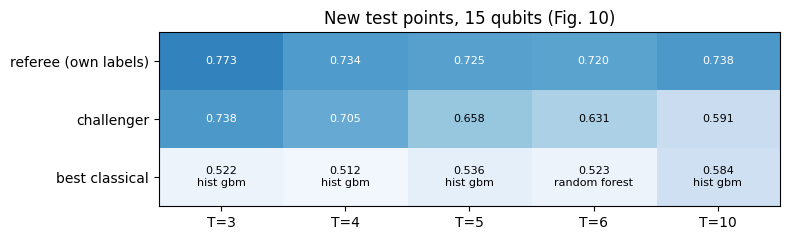

In [10]:
rows = [("referee (own labels)", "pqk (base, self)"), ("challenger", "pqk (_2)")]
best = [max(CLASSICAL, key=lambda m: newl[f"{f}/cv/{m}"].mean()) for f in NEW]
mean = np.array([[newl[f"{f}/cv/{m}"].mean() for f in NEW] for _, m in rows] +
                [[newl[f"{f}/cv/{b}"].mean() for f, b in zip(NEW, best)]])
fig, ax = plt.subplots(figsize=(8, 2.5))
ax.imshow(mean, cmap="Blues", vmin=0.5, vmax=0.9, aspect="auto")
for i in range(3):
    for j in range(len(NEW)):
        ax.text(j, i, f"{mean[i, j]:.3f}" + (f"\n{best[j]}" if i == 2 else ""), ha="center", va="center", fontsize=8,
                color="w" if mean[i, j] > 0.7 else "k")
ax.set(xticks=range(5), xticklabels=[f"T={t}" for t in (3, 4, 5, 6, 10)], yticks=range(3),
       yticklabels=["referee (own labels)", "challenger", "best classical"], title="New test points, 15 qubits (Fig. 10)")
plt.tight_layout()
plt.show()

## Figs. 5 and 6: data size (15 qubits, T=3)
Mean over labellings, then mean and std over 10 subsamples. Classical: best of 10 test-tuned models per run.

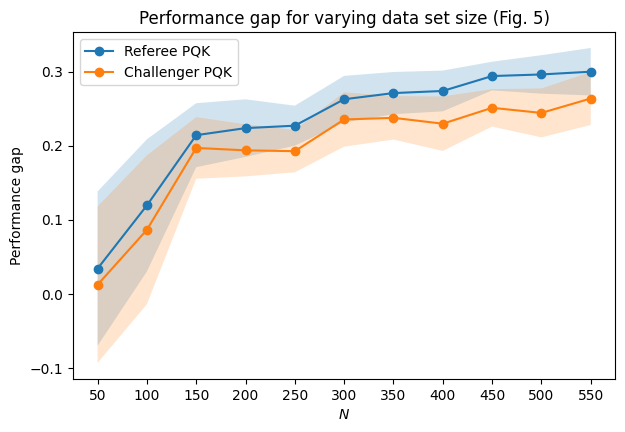

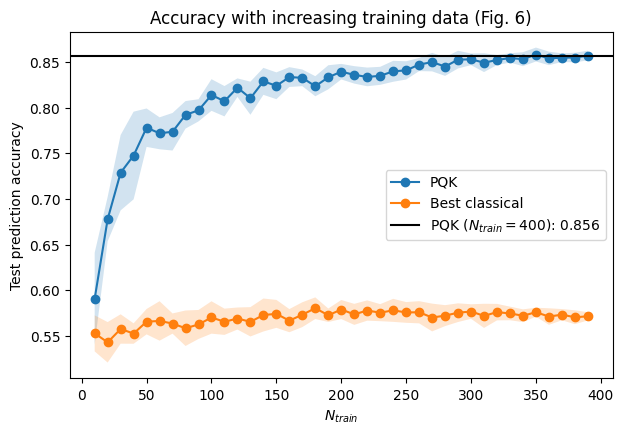

In [11]:
ds = np.load(f"{DATA}/accuracies/datasize.npz")
ref, chal = np.load(f"{DATA}/datasize/referee.npz"), np.load(f"{DATA}/datasize/challenger.npz")
N = [50 * (i + 1) for i in range(11)]
NTR = list(range(10, 400, 10))
F15 = {s: feats(15, 3, s) for s in "eg"}
L = chal["labels"]
line = np.mean([challenger_accuracy(F15["g"][:400], F15["g"][400:], L[k, :400], L[k, 400:]) for k in range(10)])

fig, ax = plt.subplots(figsize=(7, 4.5))
for k, name in [("e", "Referee PQK"), ("g", "Challenger PQK")]:
    diff = ds[f"ref_scores_{k}"] - ds["ref_scores_cl"]
    sd = np.hypot(ds[f"ref_err_{k}"], ds["ref_err_cl"])
    ax.plot(N, diff, "o-", label=name)
    ax.fill_between(N, diff - sd, diff + sd, alpha=0.2)
ax.set(xlabel="$N$", ylabel="Performance gap", xticks=N, title="Performance gap for varying data set size (Fig. 5)")
ax.legend()
plt.show()

fig, ax = plt.subplots(figsize=(7, 4.5))
for k, name in [("q", "PQK"), ("cl", "Best classical")]:
    mean, sd = ds[f"{k}_scores"], ds[f"{k}_err"]
    ax.plot(NTR, mean, "o-", label=name)
    ax.fill_between(NTR, mean - sd, mean + sd, alpha=0.2)
ax.axhline(line, color="k", label=f"PQK ($N_{{train}}=400$): {line:.3f}")
ax.set(xlabel="$N_{train}$", ylabel="Test prediction accuracy", title="Accuracy with increasing training data (Fig. 6)")
ax.legend()
plt.show()

## Checks
**Why.** The accuracies used above were computed with our own code, which is not public. So you don't have to
trust them, this section recomputes some of them here, from the released features, labels and splits, using only
the models defined in this notebook.

**How.** Each check prints the recomputed and the stored accuracy, and stops the notebook if they differ by 0.001
or more.

- Passing means the stored numbers follow from the released data and the methods in the paper.
- A failure means the data or the stored numbers are wrong.
- Not covered: how the labels were made (they are given) and the hardware runs (the features are given). Of the
  classical models, only the best CV-tuned one behind each gap (Tables II and V) is recomputed; the test-tuned
  accuracies and the other models are stored only.

The first two cells recompute fixed points (one per table and figure). The cells under "Random checks" recompute
randomly chosen points: a single run of any stored PQK accuracy (Tables II–V, MPS), a single run of the best classical
model behind a CV gap (Tables II and V), or one data size of Fig. 5 or 6. Change `SEED` there to check other points;
every point has been checked to pass.

In [12]:
splits = np.load(f"{DATA}/splits.npz")


def runs100(labels, f=None, x=None, model=None, gstar=None):
    """Mean test accuracy over the 100 runs: PQK on features f, or one CV-tuned classical model on inputs x."""
    jobs = []
    for s in range(10):
        ix = splits["sample_idx"][s]
        for k in range(10):
            tr, te = splits["train_idx"][s * 10 + k], splits["test_idx"][s * 10 + k]
            y = labels[s, k]
            if model is None:
                jobs.append(delayed(challenger_accuracy)(f[ix][tr], f[ix][te], y[tr], y[te]))
            else:
                xc = x[ix]
                jobs.append(delayed(classical_accuracy)(model, xc[tr], xc[te], y[tr], y[te], gamma_grid(xc), gstar[s]))
    return np.mean(Parallel(n_jobs=-1)(jobs))


def compare(what, got, stored):
    print(f"{what:<45} refit {got:.3f}  stored {stored:.3f}  diff {got - stored:+.3f}")
    assert abs(got - stored) < 1e-3, what


lab = lambda path: np.load(f"{DATA}/{path}.npz")["labels"]
for fam, t in [("15q", 3), ("15q_10trot", 10)]:
    compare(f"Table II {fam} challenger", runs100(lab(f"labels/{fam}"), feats(15, t, "g")), acc(fam, "pqk (_2)").mean())
l10 = np.load(f"{DATA}/labels/15q_10trot.npz")
compare("Table II 15q_10trot hist gbm",
        runs100(l10["labels"], x=np.load(f"{DATA}/inputs/x_pool.npy")[:, -14:], model="hist gbm", gstar=l10["gamma_star"]),
        acc("15q_10trot", "hist gbm").mean())
compare("Table III noiseless kernel, ideal labels", runs100(lab("labels/ideal_15q_10trot"), I), ideal["ideal"].mean())
compare("Table III Garnet (orig.), ideal labels", runs100(lab("labels/ideal_15q_10trot"), feats(15, 10, "g_orig")),
        ideal["g_orig"].mean())
compare("Table IV Garnet (orig.) on ZNE labels", runs100(lab("labels/15q_10trot_zne"), feats(15, 10, "g_orig")),
        swap["15q_10trot_zne/g_orig"].mean())
compare("MPS challenger, 45q T=10", runs100(lab("labels/45q_10trot"), feats(45, 10, "MPS")), mps.mean())
compare("Table V challenger, T=3", runs100(lab("labels_new/15q"), feats(15, 3, "g")), newl["15q/cv/pqk (_2)"].mean())
l6 = np.load(f"{DATA}/labels_new/15q_6trot.npz")
compare("Table V 15q_6trot random forest",
        runs100(l6["labels"], x=np.load(f"{DATA}/inputs/x_pool.npy")[:, -14:], model="random forest",
                gstar=l6["gamma_star"]),
        newl["15q_6trot/cv/random forest"].mean())

Table II 15q challenger                       refit 0.809  stored 0.809  diff +0.000


Table II 15q_10trot challenger                refit 0.683  stored 0.683  diff +0.000


Table II 15q_10trot hist gbm                  refit 0.643  stored 0.643  diff +0.000


Table III noiseless kernel, ideal labels      refit 0.863  stored 0.863  diff +0.000


Table III Garnet (orig.), ideal labels        refit 0.745  stored 0.745  diff +0.000


Table IV Garnet (orig.) on ZNE labels         refit 0.740  stored 0.740  diff +0.000


MPS challenger, 45q T=10                      refit 0.717  stored 0.717  diff +0.000


Table V challenger, T=3                       refit 0.738  stored 0.738  diff +0.000


Table V 15q_6trot random forest               refit 0.523  stored 0.523  diff +0.000


In [13]:
def fig6(n):
    f = F15["g"]
    return np.mean(Parallel(n_jobs=-1)(delayed(challenger_accuracy)(f[tr], f[400:], L[k, tr], L[k, 400:])
                                       for tr in chal[f"N{n}/train_idx"] for k in range(10)))


def fig5(n, kind):
    ix, Y, m = ref[f"N{n}/sample_idx"], ref[f"N{n}/labels"], 2 * n // 3
    f = F15[kind]
    return np.mean(Parallel(n_jobs=-1)(delayed(challenger_accuracy)(f[ix[j]][:m], f[ix[j]][m:], Y[j, k, :m], Y[j, k, m:])
                                       for j in range(10) for k in range(10)))


for n in (50, 200, 390):
    compare(f"Fig. 6 PQK, N_train={n}", fig6(n), ds["q_scores"][NTR.index(n)])
for n in (100, 550):
    for k, name in [("e", "referee"), ("g", "challenger")]:
        compare(f"Fig. 5 {name} PQK, N={n}", fig5(n, k), ds[f"ref_scores_{k}"][N.index(n)])

Fig. 6 PQK, N_train=50                        refit 0.778  stored 0.778  diff -0.000


Fig. 6 PQK, N_train=200                       refit 0.839  stored 0.839  diff +0.000


Fig. 6 PQK, N_train=390                       refit 0.857  stored 0.857  diff +0.000


Fig. 5 referee PQK, N=100                     refit 0.751  stored 0.751  diff +0.000


Fig. 5 challenger PQK, N=100                  refit 0.718  stored 0.718  diff -0.000


Fig. 5 referee PQK, N=550                     refit 0.866  stored 0.866  diff +0.000


Fig. 5 challenger PQK, N=550                  refit 0.830  stored 0.830  diff +0.000


### Random checks

Change `SEED` to check other points, and `PICKS` to check more of them.

In [14]:
SEED = 0
PICKS = 5

In [15]:


def feature_files(fam):
    """(n, T, challenger, referee) feature suffixes for a family in gap_test.npz."""
    n, rest = fam.split("q", 1)
    t = 3 if rest == "" else int(rest[1:].split("trot")[0])  # key "15q" is T=3
    if n != "15":
        return int(n), t, "chainB", "chainA"
    mit = fam.split("trot_")[1] if "trot_" in fam else None
    return 15, t, *{None: ("g", "e"), "orig": ("g_orig", "e_orig"), "zne": ("zne_g", "zne_e"),
                    "rem": ("rem_g", "rem_e"), "apt": ("apt_g", "apt_e")}[mit]


def one_run(f, labels, i):
    """PQK accuracy of run i = subsample s, labelling k."""
    s, k = divmod(i, 10)
    f, y = f[splits["sample_idx"][s]], labels[s, k]
    tr, te = splits["train_idx"][i], splits["test_idx"][i]
    return challenger_accuracy(f[tr], f[te], y[tr], y[te])


# Every stored PQK accuracy: (name, features, labels, the 100 stored runs)
stored = []
for fam in FAMILIES:
    n, t, ch, rf = feature_files(fam)
    stored += [(f"Table II {fam} challenger", (n, t, ch), f"labels/{fam}", acc(fam, "pqk (_2)")),
               (f"Table II {fam} referee", (n, t, rf), f"labels/{fam}", acc(fam, "pqk (base, self)"))]
stored += [(f"Table III {k}, ideal labels", (15, 10, "IDEALSIM600" if k == "ideal" else k), "labels/ideal_15q_10trot",
            ideal[k]) for k in ideal.files if k not in ("laplacian", "hist gbm")]
stored += [(f"Table IV {k.split('/')[1]} on {k.split('/')[0]} labels", (15, 10, k.split("/")[1]),
            f"labels/{k.split('/')[0]}", swap[k]) for k in swap.files]
stored += [("MPS challenger, 45q T=10", (45, 10, "MPS"), "labels/45q_10trot", mps)]
stored += [(f"Table V {fam} {role}", (15, T_OF[fam], suf), f"labels_new/{fam}", newl[f"{fam}/cv/{m}"])
           for fam in NEW for role, suf, m in (("challenger", "g", "pqk (_2)"), ("referee", "e", "pqk (base, self)"))]


def one_classical_run(n, labels, model, i):
    """CV-tuned classical accuracy of run i, on the n-1 PCA inputs of an n-qubit family."""
    s, k = divmod(i, 10)
    lb = np.load(f"{DATA}/{labels}.npz")
    x, y = np.load(f"{DATA}/inputs/x_pool.npy")[:, -(n - 1):][splits["sample_idx"][s]], lb["labels"][s, k]
    tr, te = splits["train_idx"][i], splits["test_idx"][i]
    return classical_accuracy(model, x[tr], x[te], y[tr], y[te], gamma_grid(x), lb["gamma_star"][s])


# The best classical model behind each gap: (name, n, labels, model, the 100 stored runs)
classical = [(f"Table II {fam} {best_classical(fam)}", int(fam.split("q")[0]), f"labels/{fam}", best_classical(fam),
              acc(fam, best_classical(fam))) for fam in FAMILIES]
for fam in NEW:
    m = max(CLASSICAL, key=lambda m: newl[f"{fam}/cv/{m}"].mean())
    classical.append((f"Table V {fam} {m}", 15, f"labels_new/{fam}", m, newl[f"{fam}/cv/{m}"]))
sizes = [("Fig. 6", n, None) for n in NTR] + [("Fig. 5", n, k) for n in N for k in "eg"]

rng = np.random.default_rng(SEED)
for j in rng.choice(len(stored) + len(classical) + len(sizes), PICKS, replace=False):
    if j < len(stored):
        name, f, labels, runs = stored[j]
        i = int(rng.integers(100))
        compare(f"{name}, run {i}", one_run(feats(*f), lab(labels), i), runs[i])
    elif j < len(stored) + len(classical):
        name, n, labels, model, runs = classical[j - len(stored)]
        i = int(rng.integers(100))
        compare(f"{name}, run {i}", one_classical_run(n, labels, model, i), runs[i])
    else:
        fig, n, k = sizes[j - len(stored) - len(classical)]
        if fig == "Fig. 6":
            compare(f"Fig. 6 PQK, N_train={n}", fig6(n), ds["q_scores"][NTR.index(n)])
        else:
            compare(f"Fig. 5 {'referee' if k == 'e' else 'challenger'} PQK, N={n}", fig5(n, k),
                    ds[f"ref_scores_{k}"][N.index(n)])

Fig. 6 PQK, N_train=40                        refit 0.748  stored 0.748  diff -0.000


Table II 30q_10trot hist gbm, run 81          refit 0.660  stored 0.660  diff +0.000


Table III e_orig, ideal labels, run 64        refit 0.760  stored 0.760  diff +0.000


Table III apt_e, ideal labels, run 91         refit 0.900  stored 0.900  diff +0.000


Fig. 6 PQK, N_train=350                       refit 0.858  stored 0.858  diff +0.000
